Saving Zrzut ekranu 2025-10-14 214509.png to Zrzut ekranu 2025-10-14 214509.png


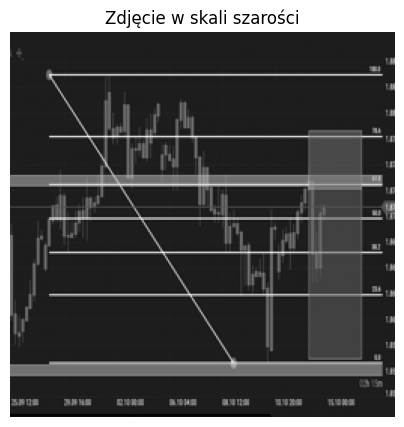

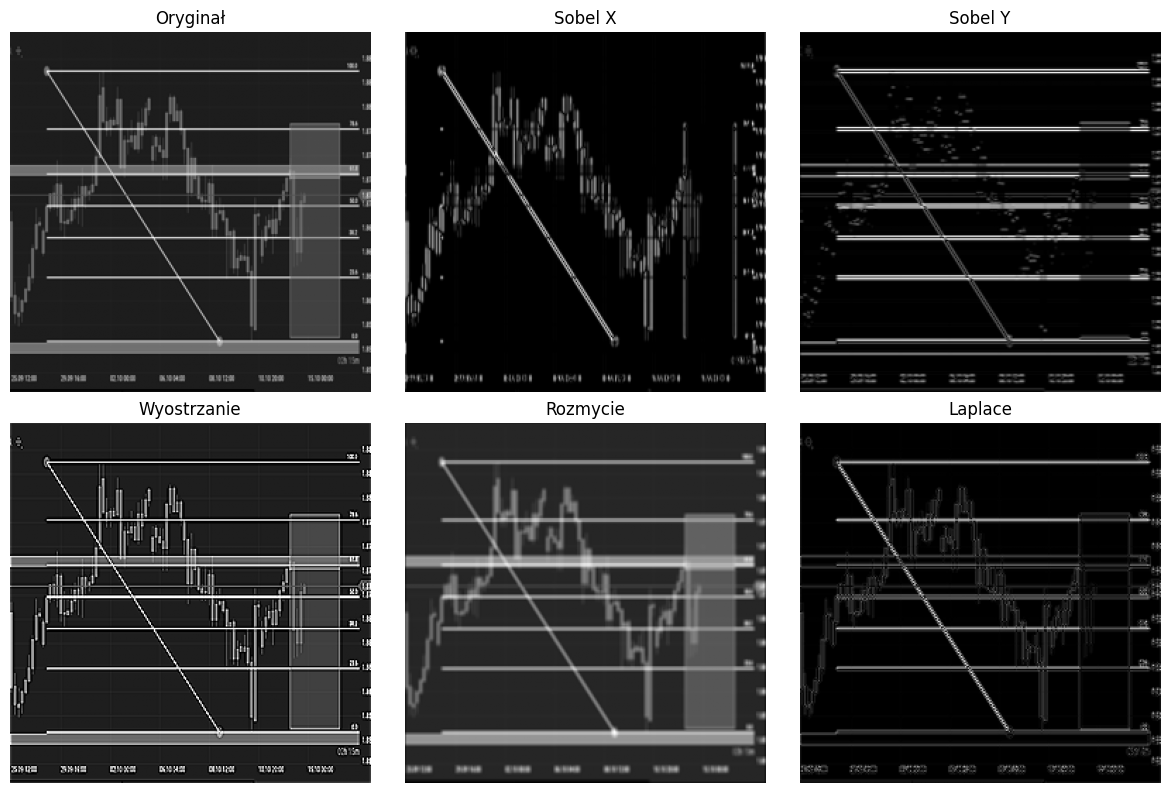

Sobel X wykrywa głównie krawędzie pionowe.
Sobel Y wykrywa głównie krawędzie poziome.
Wyostrzanie wzmacnia szczegóły obrazu.
Rozmycie wygładza obraz.
Laplace wykrywa krawędzie.

WYMIARY WYJŚCIA:


,Kernel,Stride,Padding,Dilation,Wejście,Wyjście ze wzoru,Wyjście PyTorch,Zgodność
0,3,1,1,1,256x256,256x256,256x256,True
1,3,2,1,1,256x256,128x128,128x128,True
2,5,1,2,1,256x256,256x256,256x256,True
3,3,1,2,2,256x256,256x256,256x256,True
4,7,2,3,1,256x256,128x128,128x128,True
5,5,2,0,1,256x256,126x126,126x126,True



Wzór:
out = floor((in + 2*padding - dilation*(kernel-1) - 1)
            / stride + 1)



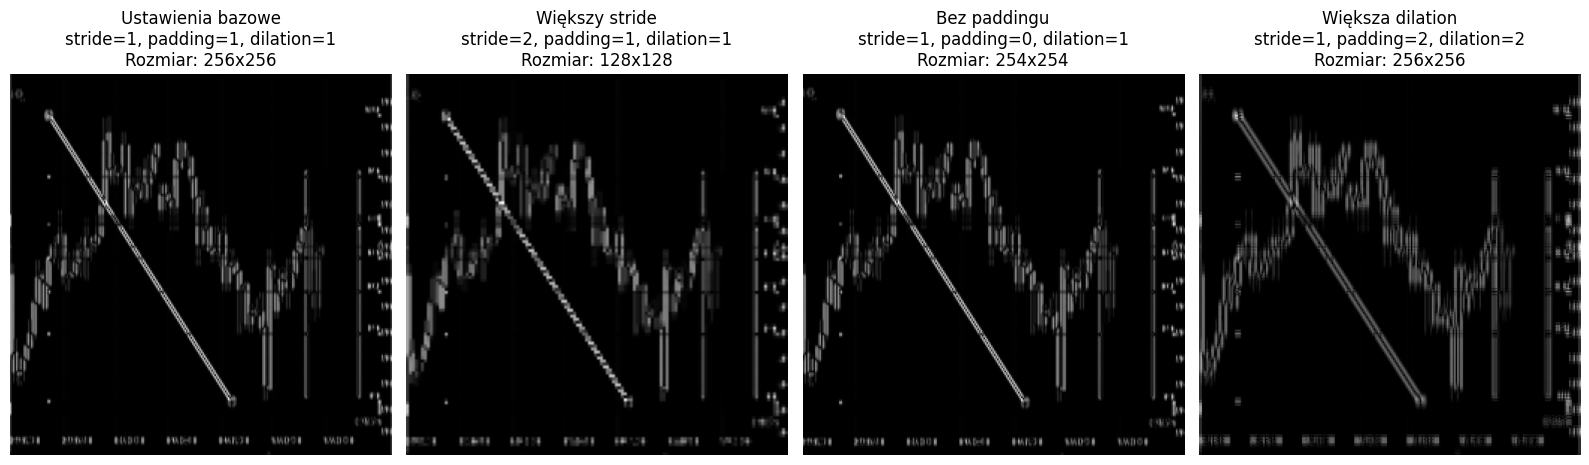


STRIDE – określa przesunięcie filtra. Większy stride
zmniejsza rozmiar mapy wyjściowej.

PADDING – dodaje piksele na brzegach obrazu.
Pozwala zachować rozmiar wyjścia.

DILATION – zwiększa odstępy między elementami filtra.
Zwiększa pole recepcyjne.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 102MB/s]


Wagi pretrenowane: True
Rozmiar map cech: torch.Size([64, 112, 112])


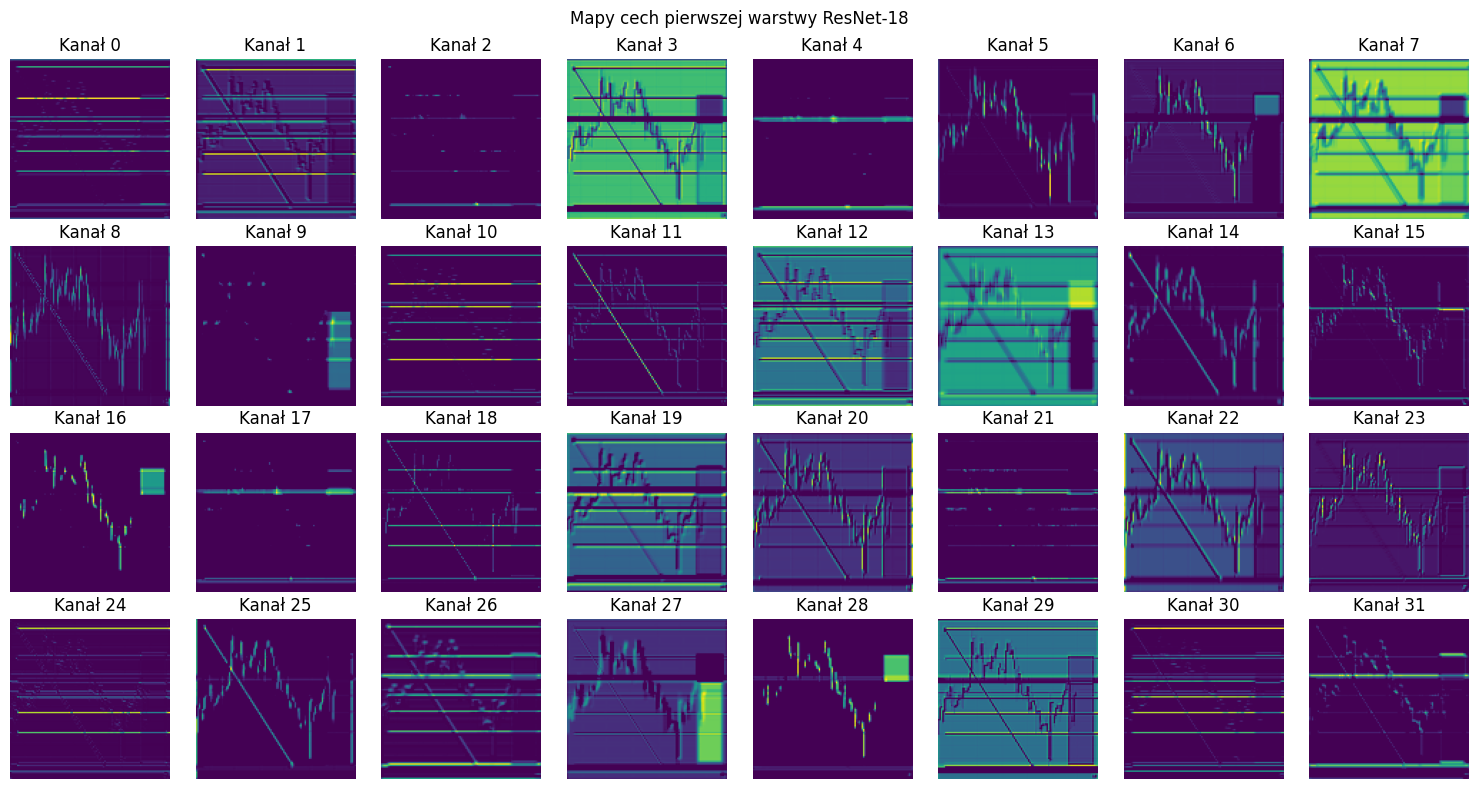


Mapy cech przedstawiają reakcje poszczególnych filtrów
na różne elementy obrazu.

Kanały mogą wykrywać krawędzie, tekstury, kontrast
i inne charakterystyczne wzorce.

Jasne obszary oznaczają silniejszą aktywację filtra.



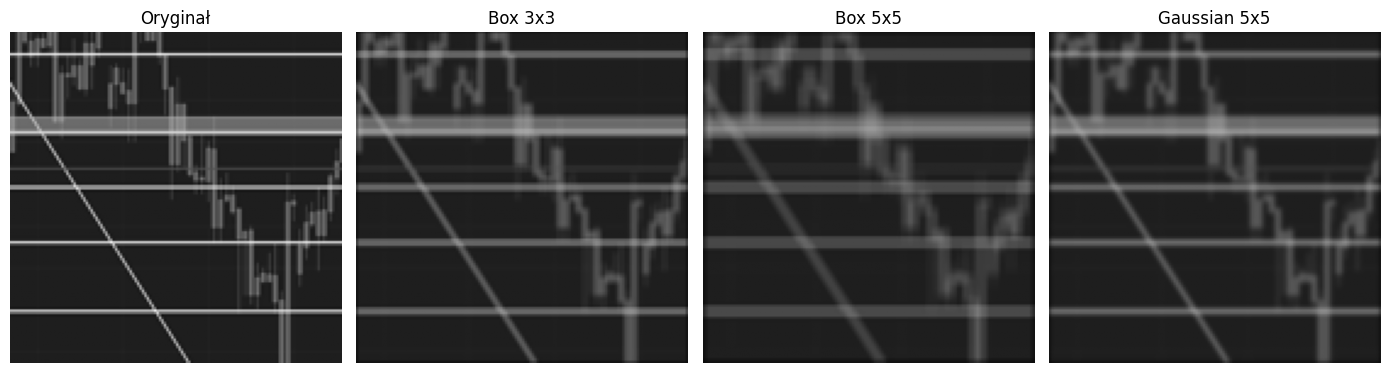

Rozmiar oryginału: torch.Size([136, 136])
Rozmiar Box 3x3: torch.Size([136, 136])
Rozmiar Box 5x5: torch.Size([136, 136])
Rozmiar Gaussian 5x5: torch.Size([136, 136])

PORÓWNANIE FILTRÓW:

BOX 3x3 – delikatne rozmycie, zachowuje więcej szczegółów.

BOX 5x5 – mocniejsze rozmycie, ponieważ uśrednia większy
obszar obrazu.

GAUSSIAN 5x5 – największe wagi przypisuje pikselom
znajdującym się blisko środka filtra. Daje naturalne
wygładzenie obrazu.


================ WNIOSKI ================

1. Ręczne jądra splotowe pozwalają wykrywać krawędzie,
   wyostrzać oraz rozmywać obrazy.

2. Wymiary wyjścia zależą od kernel_size, stride,
   padding oraz dilation.

3. Stride zmniejsza mapę wyjściową, padding dodaje
   obramowanie, a dilation zwiększa pole recepcyjne.

4. Mapy cech pokazują reakcje filtrów sieci neuronowej
   na różne wzorce obrazu.

5. Box 3x3, Box 5x5 i Gaussian 5x5 różnią się siłą
   i sposobem rozmywania obrazu.




In [1]:


import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image
from pathlib import Path
from torchvision.models import resnet18, ResNet18_Weights



IMAGE_PATH = "moje_zdjecie.jpg"

if Path(IMAGE_PATH).exists():
    img = Image.open(IMAGE_PATH).convert("RGB")
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        img = Image.open(next(iter(uploaded))).convert("RGB")
    except Exception:
        print("Brak zdjęcia. Używam obrazu przykładowego.")
        y, x = np.mgrid[0:256, 0:256]
        arr = np.zeros((256, 256), dtype=np.uint8) + 35
        arr[45:210, 45:210] = 190
        arr[80:175, 80:175] = 245
        arr[:, 125:132] = 80
        img = Image.fromarray(arr).convert("RGB")

img = img.resize((256, 256))

image = torch.tensor(
    np.array(img), dtype=torch.float32
).permute(2, 0, 1).unsqueeze(0) / 255.0

gray = image.mean(dim=1, keepdim=True)

plt.figure(figsize=(5, 5))
plt.imshow(gray[0, 0], cmap="gray")
plt.title("Zdjęcie w skali szarości")
plt.axis("off")
plt.show()



def kernel(values):
    return torch.tensor(values, dtype=torch.float32).reshape(
        1, 1, len(values), len(values)
    )


sobel_x = kernel([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y = kernel([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])

sharpen = kernel([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

blur = torch.ones((1, 1, 3, 3)) / 9

laplace = kernel([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
])

result_sobel_x = F.conv2d(gray, sobel_x, padding=1).abs()
result_sobel_y = F.conv2d(gray, sobel_y, padding=1).abs()
result_sharpen = F.conv2d(gray, sharpen, padding=1).clamp(0, 1)
result_blur = F.conv2d(gray, blur, padding=1)
result_laplace = F.conv2d(gray, laplace, padding=1).abs()

results = [
    ("Oryginał", gray),
    ("Sobel X", result_sobel_x),
    ("Sobel Y", result_sobel_y),
    ("Wyostrzanie", result_sharpen),
    ("Rozmycie", result_blur),
    ("Laplace", result_laplace)
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (name, result) in zip(axes.flat, results):
    ax.imshow(result[0, 0].detach().numpy(), cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Sobel X wykrywa głównie krawędzie pionowe.")
print("Sobel Y wykrywa głównie krawędzie poziome.")
print("Wyostrzanie wzmacnia szczegóły obrazu.")
print("Rozmycie wygładza obraz.")
print("Laplace wykrywa krawędzie.")



def output_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1) // s + 1


IN_SIZE = gray.shape[-1]

configurations = [
    {"k": 3, "s": 1, "p": 1, "d": 1},
    {"k": 3, "s": 2, "p": 1, "d": 1},
    {"k": 5, "s": 1, "p": 2, "d": 1},
    {"k": 3, "s": 1, "p": 2, "d": 2},
    {"k": 7, "s": 2, "p": 3, "d": 1},
    {"k": 5, "s": 2, "p": 0, "d": 1}
]

rows = []

x_test = torch.randn(1, 1, IN_SIZE, IN_SIZE)

for c in configurations:

    calculated = output_dim(IN_SIZE, **c)

    conv = torch.nn.Conv2d(
        1, 1,
        kernel_size=c["k"],
        stride=c["s"],
        padding=c["p"],
        dilation=c["d"]
    )

    actual = conv(x_test).shape[-1]

    rows.append({
        "Kernel": c["k"],
        "Stride": c["s"],
        "Padding": c["p"],
        "Dilation": c["d"],
        "Wejście": f"{IN_SIZE}x{IN_SIZE}",
        "Wyjście ze wzoru": f"{calculated}x{calculated}",
        "Wyjście PyTorch": f"{actual}x{actual}",
        "Zgodność": calculated == actual
    })

df = pd.DataFrame(rows)
print("\nWYMIARY WYJŚCIA:")
display(df)

print("""
Wzór:
out = floor((in + 2*padding - dilation*(kernel-1) - 1)
            / stride + 1)
""")



settings = [
    (1, 1, 1, "Ustawienia bazowe"),
    (2, 1, 1, "Większy stride"),
    (1, 0, 1, "Bez paddingu"),
    (1, 2, 2, "Większa dilation")
]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (s, p, d, name) in zip(axes, settings):

    output = F.conv2d(
        gray,
        sobel_x,
        stride=s,
        padding=p,
        dilation=d
    )

    ax.imshow(output[0, 0].abs().detach().numpy(), cmap="gray")

    ax.set_title(
        f"{name}\n"
        f"stride={s}, padding={p}, dilation={d}\n"
        f"Rozmiar: {output.shape[-2]}x{output.shape[-1]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print("""
STRIDE – określa przesunięcie filtra. Większy stride
zmniejsza rozmiar mapy wyjściowej.

PADDING – dodaje piksele na brzegach obrazu.
Pozwala zachować rozmiar wyjścia.

DILATION – zwiększa odstępy między elementami filtra.
Zwiększa pole recepcyjne.
""")



try:
    weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=weights).eval()
    pretrained = True

except Exception as e:
    print("Nie udało się pobrać wag:", e)
    model = resnet18(weights=None).eval()
    pretrained = False

if pretrained:
    preprocess = weights.transforms()
    input_image = preprocess(img).unsqueeze(0)
else:
    input_image = F.interpolate(
        image,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

with torch.no_grad():
    features = torch.relu(model.conv1(input_image))[0]

print("Wagi pretrenowane:", pretrained)
print("Rozmiar map cech:", features.shape)

fig, axes = plt.subplots(4, 8, figsize=(15, 8))

for i, ax in enumerate(axes.flat):

    ax.imshow(features[i].cpu().numpy(), cmap="viridis")
    ax.set_title(f"Kanał {i}")
    ax.axis("off")

plt.suptitle("Mapy cech pierwszej warstwy ResNet-18")
plt.tight_layout()
plt.show()

print("""
Mapy cech przedstawiają reakcje poszczególnych filtrów
na różne elementy obrazu.

Kanały mogą wykrywać krawędzie, tekstury, kontrast
i inne charakterystyczne wzorce.

Jasne obszary oznaczają silniejszą aktywację filtra.
""")


box3 = torch.ones((1, 1, 3, 3)) / 9
box5 = torch.ones((1, 1, 5, 5)) / 25

gaussian_values = torch.tensor([
    [1, 4, 6, 4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1, 4, 6, 4, 1]
], dtype=torch.float32)

gaussian5 = (
    gaussian_values / gaussian_values.sum()
).reshape(1, 1, 5, 5)


crop = gray[:, :, 60:196, 60:196]

result_box3 = F.conv2d(
    crop, box3,
    stride=1,
    padding=1,
    dilation=1
)

result_box5 = F.conv2d(
    crop, box5,
    stride=1,
    padding=2,
    dilation=1
)

result_gaussian = F.conv2d(
    crop, gaussian5,
    stride=1,
    padding=2,
    dilation=1
)

comparisons = [
    ("Oryginał", crop),
    ("Box 3x3", result_box3),
    ("Box 5x5", result_box5),
    ("Gaussian 5x5", result_gaussian)
]

fig, axes = plt.subplots(1, 4, figsize=(14, 5))

for ax, (name, result) in zip(axes, comparisons):

    ax.imshow(
        result[0, 0].detach().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Rozmiar oryginału:", crop.shape[-2:])
print("Rozmiar Box 3x3:", result_box3.shape[-2:])
print("Rozmiar Box 5x5:", result_box5.shape[-2:])
print("Rozmiar Gaussian 5x5:", result_gaussian.shape[-2:])

print("""
PORÓWNANIE FILTRÓW:

BOX 3x3 – delikatne rozmycie, zachowuje więcej szczegółów.

BOX 5x5 – mocniejsze rozmycie, ponieważ uśrednia większy
obszar obrazu.

GAUSSIAN 5x5 – największe wagi przypisuje pikselom
znajdującym się blisko środka filtra. Daje naturalne
wygładzenie obrazu.
""")


print("""
================ WNIOSKI ================

1. Ręczne jądra splotowe pozwalają wykrywać krawędzie,
   wyostrzać oraz rozmywać obrazy.

2. Wymiary wyjścia zależą od kernel_size, stride,
   padding oraz dilation.

3. Stride zmniejsza mapę wyjściową, padding dodaje
   obramowanie, a dilation zwiększa pole recepcyjne.

4. Mapy cech pokazują reakcje filtrów sieci neuronowej
   na różne wzorce obrazu.

5. Box 3x3, Box 5x5 i Gaussian 5x5 różnią się siłą
   i sposobem rozmywania obrazu.

=========================================
""")